In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')

¡PyLTSpice ya estaba instalado y listo para usar!


✅ Muestras extraídas por variable:
Vr (V)        10
ID P1 (uA)    10
dtype: int64

--- Primeros 5 datos ---
     Vr (V)  ID P1 (uA)
0  0.703736     11.4321
1  0.703289     11.4248
2  0.704098     11.4381
3  0.702668     11.4146
4  0.707562     11.4949

--- Resumen Estadístico ---
          Vr (V)  ID P1 (uA)
count  10.000000   10.000000
mean    0.704351   11.442200
std     0.003110    0.051008
min     0.698734   11.350100
max     0.708691   11.513400


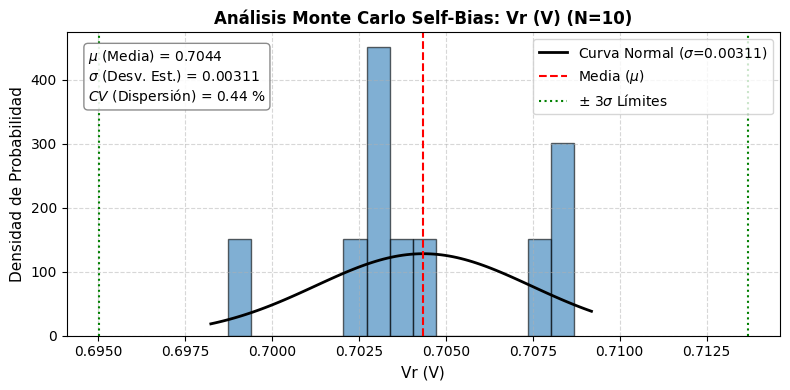

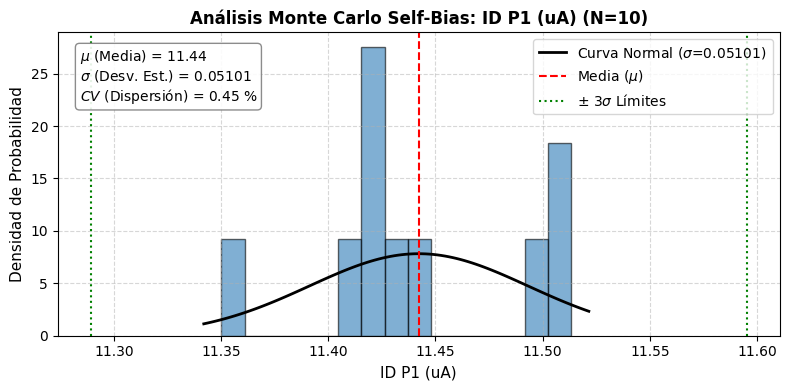

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

# ==============================================================================
# 1. CARGAR Y EXTRAER LOS DATOS DEL SELF-BIAS
# ==============================================================================
ruta_archivo = "/headless/.xschem/simulations/self_bias_mc.txt"

if not os.path.exists(ruta_archivo):
    print(f"⚠️ Archivo no encontrado en: {ruta_archivo}")
    exit()

with open(ruta_archivo, 'r') as f:
    texto = f.read()

# Regex estricto que solo atrapa números reales en la misma línea
def extraer(variable, texto):
    patron = rf"{variable}[ \t]*=[ \t]*([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
    encontrados = re.findall(patron, texto)
    valores = []
    for x in encontrados:
        try:
            valores.append(float(x))
        except ValueError:
            pass
    return valores

# Diccionario con todos los parámetros a buscar en el archivo .txt
candidatos = {
    'Vr (V)': extraer('vgs', texto),
    'ID P1 (A)':   extraer('id_p1', texto),   
}

# Filtramos solo las variables que tengan datos válidos
datos_extraidos = {k: v for k, v in candidatos.items() if len(v) > 0}

if not datos_extraidos:
    print("⚠️ No se encontró ningún dato válido en el archivo de texto.")
    exit()

# Convertir la corriente de Amperios a microamperios (uA)
if 'ID P1 (A)' in datos_extraidos:
    datos_extraidos['ID P1 (uA)'] = [val * 1e6 for val in datos_extraidos['ID P1 (A)']]
    del datos_extraidos['ID P1 (A)'] 

# Calculamos Ibias a partir de VR si está disponible
if 'VR P1 (V)' in datos_extraidos and 'Ibias P1 (uA)' not in datos_extraidos:
    datos_extraidos['Ibias Calc P1 (uA)'] = [(vr / 14500.0) * 1e6 for vr in datos_extraidos['VR P1 (V)']]

# Creamos el DataFrame
df_mc = pd.DataFrame.from_dict(datos_extraidos, orient='index').T

print(f"✅ Muestras extraídas por variable:\n{df_mc.count()}\n")
print("--- Primeros 5 datos ---")
print(df_mc.head(5))
print("\n--- Resumen Estadístico ---")
print(df_mc.describe().loc[['count', 'mean', 'std', 'min', 'max']])

# ==============================================================================
# 2. FUNCIÓN PARA GRAFICAR HISTOGRAMAS Y CAMPANA DE GAUSS
# ==============================================================================
def graficar_gauss(df, columna):
    # Quitamos datos nulos por si alguna simulación falló
    datos = df[columna].dropna()
    if len(datos) < 2:
        print(f"ℹ️ '{columna}' tiene menos de 2 datos (N={len(datos)}). Sube mc_runs en Ngspice para graficar.")
        return

    # Cálculos estadísticos
    mu = np.mean(datos)            # Media
    sigma = np.std(datos, ddof=1)  # Desviación estándar
    cv = (sigma / abs(mu)) * 100 if mu != 0 else 0  # Coeficiente de variación (%)

    # Configuración del gráfico
    fig, ax = plt.subplots(figsize=(8, 4))

    # Histograma de los datos reales
    count, bins, ignored = ax.hist(datos, bins=15, density=True, alpha=0.6, color='#2c7bb6', edgecolor='black')

    # Curva teórica de Gauss
    if sigma > 0:
        xmin, xmax = ax.get_xlim()
        x = np.linspace(xmin, xmax, 100)
        p = stats.norm.pdf(x, mu, sigma)
        # Añadimos la Desviación Estándar explícitamente a la leyenda
        ax.plot(x, p, 'k', linewidth=2, label=fr'Curva Normal ($\sigma$={sigma:.4g})')

    # Líneas verticales para Media y Límites de 3 Sigma (99.7% de los chips)
    ax.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=fr'Media ($\mu$)')
    ax.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=fr'$\pm$ 3$\sigma$ Límites')
    ax.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5)

    # -------------------------------------------------------------------------
    # NUEVO: Caja de texto con las estadísticas exactas (esquina superior izq)
    # -------------------------------------------------------------------------
    texto_estadisticas = '\n'.join((
        fr'$\mu$ (Media) = {mu:.4g}',
        fr'$\sigma$ (Desv. Est.) = {sigma:.4g}',
        fr'$CV$ (Dispersión) = {cv:.2f} %'
    ))
    
    props = dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='gray')
    ax.text(0.03, 0.95, texto_estadisticas, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=props)

    # Formato visual
    ax.set_title(f'Análisis Monte Carlo Self-Bias: {columna} (N={len(datos)})', fontsize=12, fontweight='bold')
    ax.set_xlabel(columna, fontsize=11)
    ax.set_ylabel('Densidad de Probabilidad', fontsize=11)
    
    # Movemos la leyenda un poco para que no choque con la caja de texto
    ax.legend(loc='upper right')
    ax.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

# ==============================================================================
# 3. GENERAR EL REPORTE VISUAL
# ==============================================================================
for columna in df_mc.columns:
    graficar_gauss(df_mc, columna)